# Dataset summary

Counts and simple comparisons for the four spatial datasets used in the benchmark. Spatial cell-type counts use the same annotations as the Figure 2 dataset views. Reference-cell counts use the matching scRNA-seq reference; the four aging-brain donor reference files are summed.

The plotted spatial gene count is the number of distinct features across the dataset's spatial slices. Cell counts are totals over slices, so replicate sections are counted separately.

In [2]:
from pathlib import Path
import h5py
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

DATA_ROOT = Path('/work/magroup/skrieger/Syndri/data/datasets')

# Match the spatial and reference inputs used by the Figure 2 dataset views.
DATASETS = [
    dict(key='agingbrain_merfish', label='AM',
         spatial_dir=DATA_ROOT/'agingbrain_merfish/interim/spatial', spatial_pattern='*.h5ad',
         cell_type='cell_type',
         reference_paths=sorted((DATA_ROOT/'agingbrain_merfish/interim/single-cell/rctd_donor_references').glob('reference_donor_*.h5ad'))),
    dict(key='brain_merfish', label='BM',
         spatial_dir=DATA_ROOT/'brain_merfish/results/final', spatial_pattern='*.h5ad',
         cell_type='class',
         reference_paths=[DATA_ROOT/'brain_merfish/interim/single-cell/sc_integrated_mapped-Zhuang-ABCA-4.003.h5ad']),
    dict(key='nsclc_cosmx', label='NC',
         spatial_dir=DATA_ROOT/'nsclc_cosmx/results/final', spatial_pattern='*.h5ad',
         cell_type='cell_type_harmonized',
         reference_paths=[DATA_ROOT/'nsclc_cosmx/interim/single-cell/sc_integrated.h5ad']),
    dict(key='breast_xenium', label='BX',
         spatial_dir=DATA_ROOT/'breast_xenium/interim/spatial', spatial_pattern='*_rctd_annotated.h5ad',
         cell_type='harmony_cell_type',
         # The reference selected for the Xenium analyses.
         reference_paths=[DATA_ROOT/'breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad']),
]


def matrix_shape(x):
    # Read dimensions for dense or sparse AnnData matrices without loading counts.
    if isinstance(x, h5py.Group):
        return tuple(int(v) for v in x.attrs['shape'])
    return tuple(int(v) for v in x.shape)


def inspect_h5ad(path, cell_type=None):
    # Read only dimensions and annotation/feature tables; do not load expression values.
    if not path.is_file():
        raise FileNotFoundError(path)
    with h5py.File(path, 'r') as f:
        n_obs, n_vars = matrix_shape(f['X'])
        obs = ad.io.read_elem(f['obs']) if cell_type is not None else None
        var = ad.io.read_elem(f['var']) if cell_type is not None else None
    labels = set()
    if cell_type is not None:
        if cell_type not in obs.columns:
            raise KeyError(f'{path}: missing cell-type field {cell_type!r}')
        labels = set(obs[cell_type].dropna().astype(str))
    features = set(var.index.astype(str)) if var is not None else set()
    return n_obs, n_vars, labels, features


summary_rows = []
slice_rows = []
for cfg in DATASETS:
    spatial_paths = sorted(cfg['spatial_dir'].glob(cfg['spatial_pattern']))
    if not spatial_paths:
        raise FileNotFoundError(f"No spatial slices found: {cfg['spatial_dir'] / cfg['spatial_pattern']}")
    n_spatial_cells = 0
    cell_types = set()
    spatial_features = set()
    for path in spatial_paths:
        n_cells, n_genes, labels, features = inspect_h5ad(path, cell_type=cfg['cell_type'])
        n_spatial_cells += n_cells
        cell_types.update(labels)
        spatial_features.update(features)
        slice_rows.append(dict(dataset=cfg['label'], slice=path.stem, cells=n_cells, genes=n_genes))

    if not cfg['reference_paths']:
        raise FileNotFoundError(f"No reference files configured for {cfg['label']}")
    reference_cells = 0
    for path in cfg['reference_paths']:
        n_cells, _, _, _ = inspect_h5ad(path)
        reference_cells += n_cells

    summary_rows.append(dict(dataset=cfg['label'], slices=len(spatial_paths),
        cell_types=len(cell_types), spatial_cells=n_spatial_cells,
        spatial_genes=len(spatial_features), reference_cells=reference_cells,
        reference_files=len(cfg['reference_paths'])))

summary = pd.DataFrame(summary_rows).set_index('dataset')
slice_summary = pd.DataFrame(slice_rows)
display(summary.style.format('{:,}'))

,slices,cell_types,spatial_cells,spatial_genes,reference_cells,reference_files
dataset,,,,,,
AM,12,13,"126,408",374,"79,667",4
BM,3,25,"215,278","1,122","79,989",1
NC,8,15,"771,236",956,"40,362",1
BX,19,15,"1,673,926",277,"10,658",1


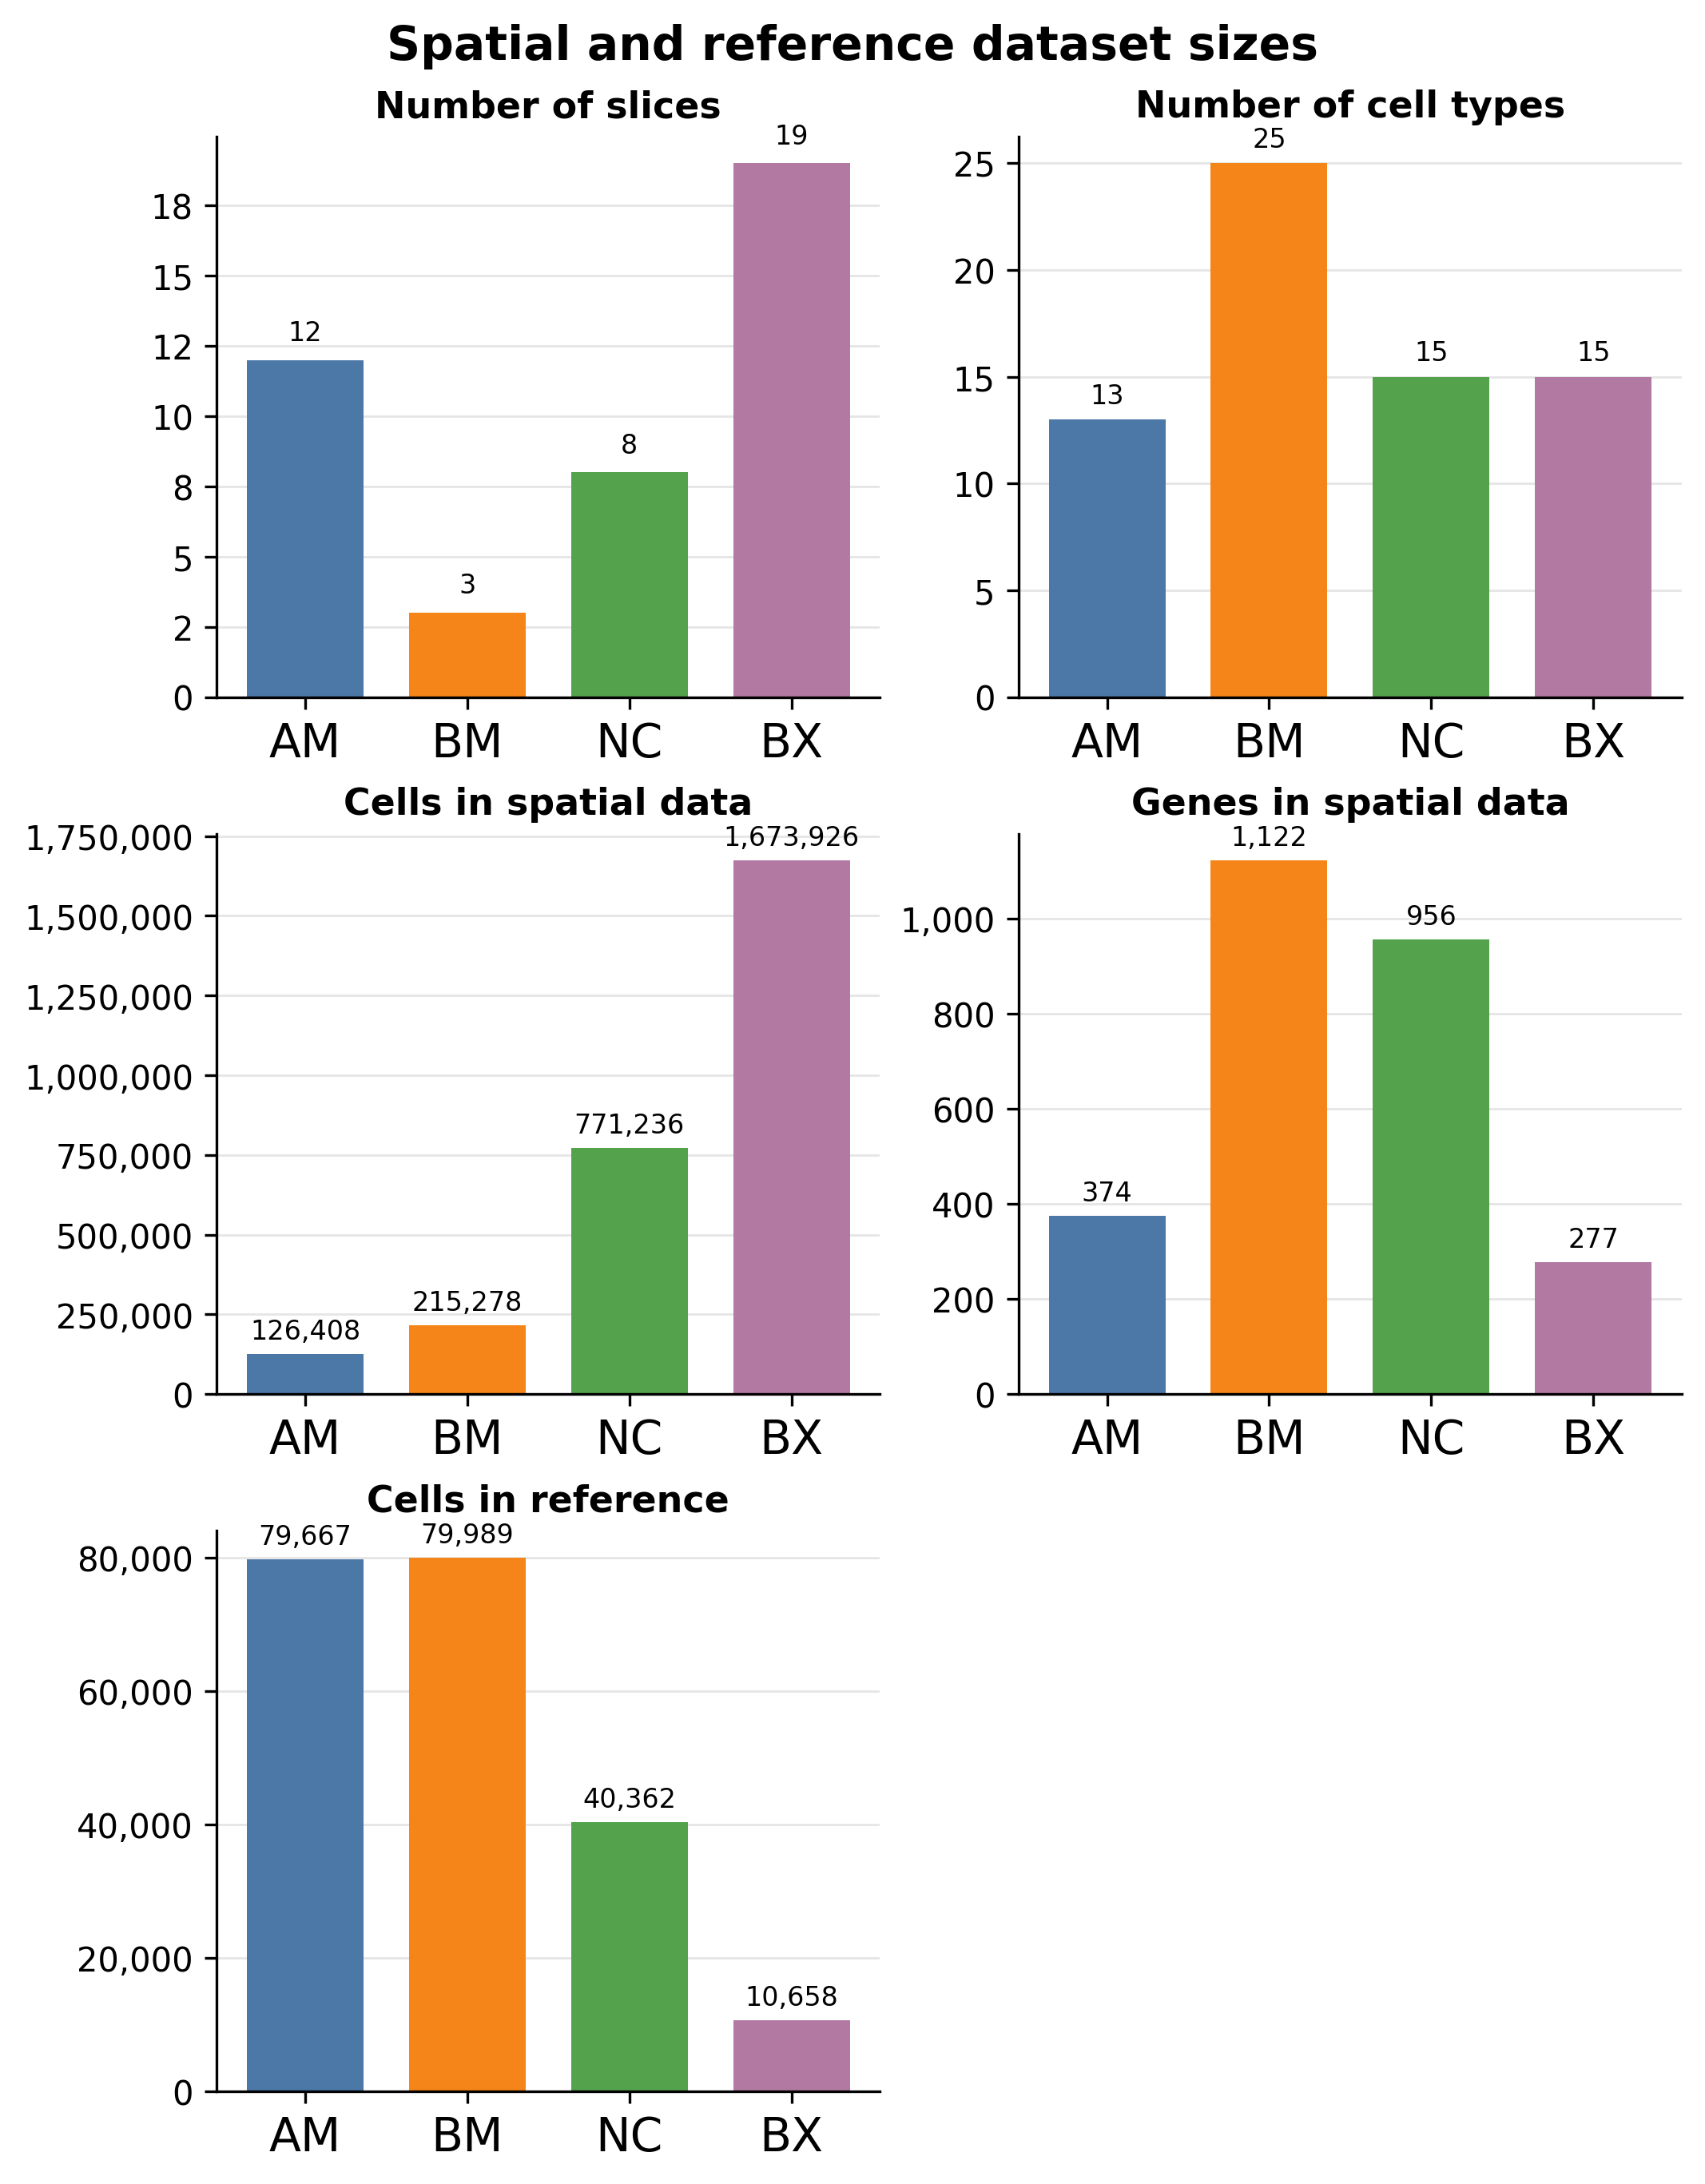

In [8]:
# One compact panel per requested statistic, with integer labels on each bar.
metrics = [
    ('slices', 'Number of slices'),
    ('cell_types', 'Number of cell types'),
    ('spatial_cells', 'Cells in spatial data'),
    ('spatial_genes', 'Genes in spatial data'),
    ('reference_cells', 'Cells in reference'),
]
colors = ['#4C78A8', '#F58518', '#54A24B', '#B279A2']
fig, axes = plt.subplots(3, 2, figsize=(7, 9), constrained_layout=True,dpi=300)
axes = axes.ravel()
for ax, (metric, title) in zip(axes, metrics):
    values = summary[metric]
    bars = ax.bar(summary.index, values, color=colors[:len(summary)], width=0.72)
    ax.set_title(title, fontsize=11, weight='semibold')
    # ax.set_ylabel('Count')
    ax.tick_params(axis='x', labelsize=14)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', color='0.9', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    offset = max(values.max() * 0.018, 0.5)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + offset,
                f'{int(value):,}', ha='center', va='bottom', fontsize=8)
for ax in axes[len(metrics):]:
    ax.remove()
fig.suptitle('Spatial and reference dataset sizes', fontsize=14, weight='bold')
plt.show()

### Counting notes

- **Slices:** number of annotated spatial AnnData files included for each dataset.
- **Cell types:** union of nonmissing labels across slices (`cell_type` for aging brain, `class` for brain MERFISH, `cell_type_harmonized` for CosMx, and `harmony_cell_type` for Xenium).
- **Spatial cells:** sum of cells across all included slices.
- **Spatial genes:** distinct feature IDs across the spatial slices.
- **Reference cells:** sum of cells across the configured reference AnnData file(s). Aging brain combines its four donor references; Xenium uses `breast_cancer_chromium_genesubset.h5ad`.